# DSCI 552 — Homework 7

**Name:** Vaidik Danda
**GitHub Username:** vaidikdanda-png
**USC ID:** 6930440811

## Imports

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import dendrogram

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1. Multi‑class and Multi‑Label Classification Using SVMs
### 1(a) Anuran Calls (MFCCs) data, 70% random training set

In [2]:
DATA_FILE = "../data/anuran_calls/Frogs_MFCCs.csv"
frogs = pd.read_csv(DATA_FILE)
FEATURES = [c for c in frogs.columns if c.startswith("MFCCs")]
LABELS = ["Family", "Genus", "Species"]

X = frogs[FEATURES].values
Y = frogs[LABELS]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.7, random_state=RANDOM_STATE)
print(f"{len(frogs)} instances, {len(FEATURES)} features | training: {len(X_train)} | test: {len(X_test)}")
print("Number of classes:", {l: frogs[l].nunique() for l in LABELS})

7195 instances, 22 features | training: 5036 | test: 2159
Number of classes: {'Family': 4, 'Genus': 8, 'Species': 10}


### 1(b) Binary relevance: one classifier per label
#### i. Exact match and Hamming score / loss
For $n$ instances with $L = 3$ labels each, let $y_{ij}$ be the true and $\hat y_{ij}$ the predicted class of label $j$
for instance $i$.
- **Exact match ratio** — fraction of instances whose labels are **all** predicted correctly:
  $\text{EM} = \frac{1}{n}\sum_i \mathbb{1}[\hat y_{i1}=y_{i1},\ \hat y_{i2}=y_{i2},\ \hat y_{i3}=y_{i3}]$.
  It is the strictest measure: a single wrong label makes the whole instance wrong.
- **Hamming loss** — fraction of individual labels predicted wrongly:
  $\text{HL} = \frac{1}{nL}\sum_i\sum_j \mathbb{1}[\hat y_{ij}\ne y_{ij}]$. It gives partial credit.
- **Hamming score** — the fraction of labels predicted correctly, $1 - \text{HL}$. (For binary label vectors,
  Sorower's survey defines it as $\frac{1}{n}\sum_i \frac{|Y_i\cap Z_i|}{|Y_i\cup Z_i|}$; here each instance has exactly
  one class per label, so the per‑label agreement $1-\text{HL}$ is used.)

In [3]:
def multilabel_scores(Y_true, Y_pred):
    wrong = (np.asarray(Y_true) != np.asarray(Y_pred))
    return {"exact match": (~wrong.any(axis=1)).mean(),
            "Hamming loss": wrong.mean(),
            "Hamming score": 1 - wrong.mean()}


RESULTS = {}


def evaluate(models, name):
    rows = []
    for split, Xs, Ys in [("train", X_train, Y_train), ("test", X_test, Y_test)]:
        pred = np.column_stack([models[l].predict(Xs) for l in LABELS])
        row = {"model": name, "set": split}
        row.update({f"{l} accuracy": (pred[:, j] == Ys[l].values).mean() for j, l in enumerate(LABELS)})
        row.update(multilabel_scores(Ys.values, pred))
        rows.append(row)
    RESULTS[name] = pd.DataFrame(rows)
    return RESULTS[name].round(4)


cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

#### ii. Gaussian‑kernel SVM, one‑versus‑all, 10‑fold CV for the penalty $C$ and kernel width $\sigma$
The kernel is $K(x,x') = \exp(-\|x-x'\|^2 / 2\sigma^2)$, i.e. `gamma` $= 1/(2\sigma^2)$. Following footnote 1, $C$ is
searched in log steps and $\sigma$ in linear steps. The attributes are used raw, since the MFCCs are already
normalized to $[-1, 1]$ (footnote 2).

In [4]:
C_GRID = [0.1, 1, 10, 100, 1000]
SIGMA_GRID = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
rbf_grid = {"estimator__C": C_GRID, "estimator__gamma": [1 / (2 * s ** 2) for s in SIGMA_GRID]}

rbf_models, rbf_params = {}, []
for l in LABELS:
    gs = GridSearchCV(OneVsRestClassifier(SVC(kernel="rbf")), rbf_grid, cv=cv10, scoring="accuracy", n_jobs=-1)
    gs.fit(X_train, Y_train[l])
    rbf_models[l] = gs.best_estimator_
    g = gs.best_params_["estimator__gamma"]
    rbf_params.append({"label": l, "C": gs.best_params_["estimator__C"], "sigma": np.sqrt(1 / (2 * g)),
                       "CV accuracy": gs.best_score_})
display(pd.DataFrame(rbf_params).round(4))
evaluate(rbf_models, "Gaussian SVM (OvR)")

,label,C,sigma,CV accuracy
0,Family,100,0.5,0.9927
1,Genus,10,0.5,0.9915
2,Species,100,0.5,0.9911


,model,set,Family accuracy,Genus accuracy,Species accuracy,exact match,Hamming loss,Hamming score
0,Gaussian SVM (OvR),train,1.0000,0.9998,1.0000,0.9998,0.0001,0.9999
1,Gaussian SVM (OvR),test,0.9954,0.9907,0.9912,0.9889,0.0076,0.9924


#### iii. L1‑penalized linear SVM (standardized attributes), 10‑fold CV for $C$
`LinearSVC(penalty="l1")` trains one‑versus‑rest classifiers with an L1 penalty on the weights.

In [8]:
C_GRID_L1 = np.logspace(-3, 1, 9)

def tune_l1(make_pipe, name):
    models, params = {}, []
    for l in LABELS:
        gs = GridSearchCV(make_pipe(), {"svm__C": C_GRID_L1}, cv=cv10, scoring="accuracy", n_jobs=-1)
        gs.fit(X_train, Y_train[l])
        models[l] = gs.best_estimator_
        params.append({"label": l, "C": gs.best_params_["svm__C"], "CV accuracy": gs.best_score_})
    display(pd.DataFrame(params).round(4))
    return evaluate(models, name)


l1_svm = lambda: LinearSVC(penalty="l1", dual=False, max_iter=5000, random_state=RANDOM_STATE)
tune_l1(lambda: Pipeline([("scale", StandardScaler()), ("svm", l1_svm())]), "L1 linear SVM")

,label,C,CV accuracy
0,Family,10.0,0.9412
1,Genus,10.0,0.9516
2,Species,10.0,0.9607


,model,set,Family accuracy,Genus accuracy,Species accuracy,exact match,Hamming loss,Hamming score
0,L1 linear SVM,train,0.9430,0.9563,0.9647,0.9249,0.0453,0.9547
1,L1 linear SVM,test,0.9282,0.9416,0.9592,0.9125,0.0570,0.9430


#### iv. L1‑penalized SVM with SMOTE
SMOTE over‑samples every minority class up to the size of the largest class. It is placed inside an `imblearn`
pipeline, so during cross‑validation it is applied only to the training folds and the validation folds stay untouched.

In [9]:
frogs[LABELS[2]].value_counts().to_frame("instances per species")

,instances per species
Species,
AdenomeraHylaedactylus,3478
HypsiboasCordobae,1121
AdenomeraAndre,672
Ameeregatrivittata,542
HypsiboasCinerascens,472
HylaMinuta,310
LeptodactylusFuscus,270
ScinaxRuber,148
OsteocephalusOophagus,114


In [10]:
tune_l1(lambda: ImbPipeline([("scale", StandardScaler()), ("smote", SMOTE(random_state=RANDOM_STATE)),
                             ("svm", l1_svm())]), "L1 linear SVM + SMOTE")

,label,C,CV accuracy
0,Family,3.1623,0.9232
1,Genus,1.0000,0.9128
2,Species,3.1623,0.9581


,model,set,Family accuracy,Genus accuracy,Species accuracy,exact match,Hamming loss,Hamming score
0,L1 linear SVM + SMOTE,train,0.9241,0.9204,0.9641,0.8697,0.0638,0.9362
1,L1 linear SVM + SMOTE,test,0.9092,0.9023,0.9579,0.8536,0.0769,0.9231


In [11]:
pd.concat(RESULTS.values()).query("set == 'test'").drop(columns="set").set_index("model").round(4)

,Family accuracy,Genus accuracy,Species accuracy,exact match,Hamming loss,Hamming score
model,,,,,,
Gaussian SVM (OvR),0.9954,0.9907,0.9912,0.9889,0.0076,0.9924
L1 linear SVM,0.9282,0.9416,0.9592,0.9125,0.0570,0.9430
L1 linear SVM + SMOTE,0.9092,0.9023,0.9579,0.8536,0.0769,0.9231


**Conclusions 1(b).** Test‑set results:

| model | Family acc. | Genus acc. | Species acc. | exact match | Hamming loss |
|---|---|---|---|---|---|
| Gaussian SVM (OvR) | 0.9954 | 0.9907 | 0.9912 | **0.9889** | **0.0076** |
| L1 linear SVM | 0.9282 | 0.9416 | 0.9592 | 0.9125 | 0.0570 |
| L1 linear SVM + SMOTE | 0.9092 | 0.9023 | 0.9579 | 0.8536 | 0.0769 |

- **The Gaussian‑kernel SVM is clearly the best** on every label: 98.9% of test calls get all three labels right, and
  fewer than 1% of individual labels are wrong. CV chose σ = 0.5 for all three labels, with C = 100 (Family, Species)
  and C = 10 (Genus). Its CV accuracy (0.991–0.993) closely matches its test accuracy.
- **The L1 linear SVM is much weaker** (exact match 91.3%). The classes are not linearly separable in the 22 MFCCs.
  Interestingly, the linear SVM does *best* on Species and worst on Family: a family or genus is a union of several
  species, each forming its own group of points, and one linear boundary cannot wrap around several separate groups.
  CV picked C = 10, the largest value in the grid; larger values were left out because the L1 solver became extremely
  slow, and the CV accuracy was already close to its test accuracy.
- **SMOTE made the L1 SVM worse here** (exact match 85.4%, Hamming loss 0.077). Balancing the classes pushes the linear
  boundaries into the large classes (e.g. *Adenomera hylaedactyla*, 48% of the data) to favour the small ones, and
  since the test set has the same imbalance as the training set, the extra errors on the large classes outweigh the
  gains on the small ones. With a linear model, class balance is not the main problem; the linear boundary is.

# 2. K‑Means Clustering on a Multi‑Class and Multi‑Label Data Set
**Choosing $k$.** For each of the 50 Monte‑Carlo runs, k‑means (k‑means++ initialization, a different random seed per
run) is fit on the **whole** data set for $k = 2, \dots, 50$, and $k$ is chosen to maximize the
**Calinski–Harabasz (CH) index**, the ratio of between‑cluster to within‑cluster dispersion (adjusted for $k$ and $n$).
$k = 1$ cannot be scored by CH (there is no between‑cluster dispersion), so the search starts at 2.

**Per run:** (a) choose $k$ and cluster; (b) find the majority Family, Genus and Species of every cluster;
(c) give every instance its cluster's majority triplet and compute the Hamming distance (number of the 3 labels that
are wrong), Hamming loss (distance / 3) and Hamming score (1 − loss).

In [12]:
X_all = frogs[FEATURES].values
Y_all = frogs[LABELS].values
K_RANGE = range(2, 51)


def one_run(seed):
    ch, fits = [], []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(X_all)
        ch.append(calinski_harabasz_score(X_all, km.labels_))
        fits.append(km.labels_)
    best = int(np.argmax(ch))
    best_k, clusters = K_RANGE[best], fits[best]
    majority = (pd.DataFrame(Y_all, columns=LABELS).assign(cluster=clusters)
                .groupby("cluster")[LABELS].agg(lambda s: s.value_counts().idxmax()))
    assigned = majority.loc[clusters].values
    dist = (assigned != Y_all).sum(axis=1)
    return {"seed": seed, "k": best_k, "Hamming distance": dist.mean(), "Hamming loss": dist.mean() / 3,
            "Hamming score": 1 - dist.mean() / 3, "ch": ch, "majority": majority, "sizes": np.bincount(clusters)}


runs = [one_run(seed) for seed in range(50)]
mc = pd.DataFrame([{k: v for k, v in r.items() if k not in ("ch", "majority", "sizes")} for r in runs])
print("Chosen k over the 50 runs:", mc["k"].value_counts().sort_index().to_dict())

Chosen k over the 50 runs: {2: 50}


### (a) CH index vs. $k$ (first run)

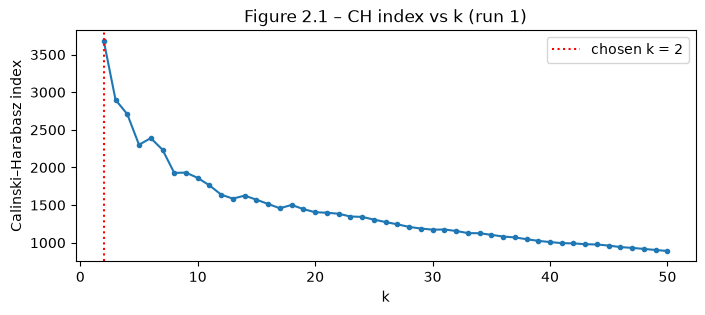

In [13]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(list(K_RANGE), runs[0]["ch"], marker="o", ms=3)
ax.axvline(runs[0]["k"], color="red", ls=":", label=f"chosen k = {runs[0]['k']}")
ax.set(xlabel="k", ylabel="Calinski–Harabasz index", title="Figure 2.1 – CH index vs k (run 1)")
ax.legend()
plt.show()

### (b) Majority labels per cluster (first run)

In [14]:
runs[0]["majority"].assign(size=runs[0]["sizes"])

,Family,Genus,Species,size
cluster,,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3598
1,Hylidae,Hypsiboas,HypsiboasCordobae,3597


### (c) Hamming distance, score and loss over the 50 runs

In [15]:
mc[["Hamming distance", "Hamming score", "Hamming loss"]].agg(["mean", "std"]).round(4)

,Hamming distance,Hamming score,Hamming loss
mean,0.8956,0.7015,0.2985
std,0.0000,0.0000,0.0000


**Answer 2.** The CH index was largest at **k = 2 in all 50 runs** (Figure 2.1). The two clusters split the data almost
in half:

| cluster | size | majority Family | majority Genus | majority Species |
|---|---|---|---|---|
| 0 | 3598 | Leptodactylidae | Adenomera | AdenomeraHylaedactylus |
| 1 | 3597 | Hylidae | Hypsiboas | HypsiboasCordobae |

Over the 50 runs, the **average Hamming distance is 0.8956 (standard deviation 0.0000)**, i.e. a Hamming loss of
0.2985 and a Hamming score of 0.7015: on average about 0.9 of the 3 labels of each call are wrong. The standard
deviation is 0 because every run chose k = 2, and with only two clusters k‑means converges to the same partition from
any random start, so all 50 runs give identical results.

With two clusters only 2 of the 10 species and 2 of the 8 genera can ever be assigned, so most of the Hamming distance
comes from species and genus; family is right much more often, because the two clusters line up with the two largest
families. Since k‑means does not see the labels, this is a reasonable but coarse match to the true label structure.

# 3. ISLR 12.6.2 (Chapter 12, Exercise 2)
Dissimilarity matrix of four observations:

| | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| 1 | | 0.3 | 0.4 | 0.7 |
| 2 | 0.3 | | 0.5 | 0.8 |
| 3 | 0.4 | 0.5 | | 0.45 |
| 4 | 0.7 | 0.8 | 0.45 | |

**(a) Complete linkage.** The smallest dissimilarity is 0.3, so 1 and 2 fuse at **0.3**. Then
$d(\{1,2\},3)=\max(0.4,0.5)=0.5$, $d(\{1,2\},4)=\max(0.7,0.8)=0.8$ and $d(3,4)=0.45$, so 3 and 4 fuse at **0.45**.
Finally $d(\{1,2\},\{3,4\})=\max(0.4,0.7,0.5,0.8)=0.8$, so the two clusters fuse at **0.8**.

**(b) Single linkage.** 1 and 2 fuse at **0.3**. Then $d(\{1,2\},3)=\min(0.4,0.5)=0.4$,
$d(\{1,2\},4)=\min(0.7,0.8)=0.7$ and $d(3,4)=0.45$, so 3 joins $\{1,2\}$ at **0.4**. Finally
$d(\{1,2,3\},4)=\min(0.7,0.8,0.45)=0.45$, so 4 joins at **0.45**.

**(c)** Cutting the complete‑linkage dendrogram into two clusters gives **{1, 2}** and **{3, 4}**.

**(d)** Cutting the single‑linkage dendrogram into two clusters gives **{1, 2, 3}** and **{4}**.

**(e)** Swapping the two leaves inside each fused pair of the complete‑linkage dendrogram gives the leaf order
2, 1, 4, 3. The fusion heights are unchanged, so the dendrogram has exactly the same meaning (Figure 3.1, right).

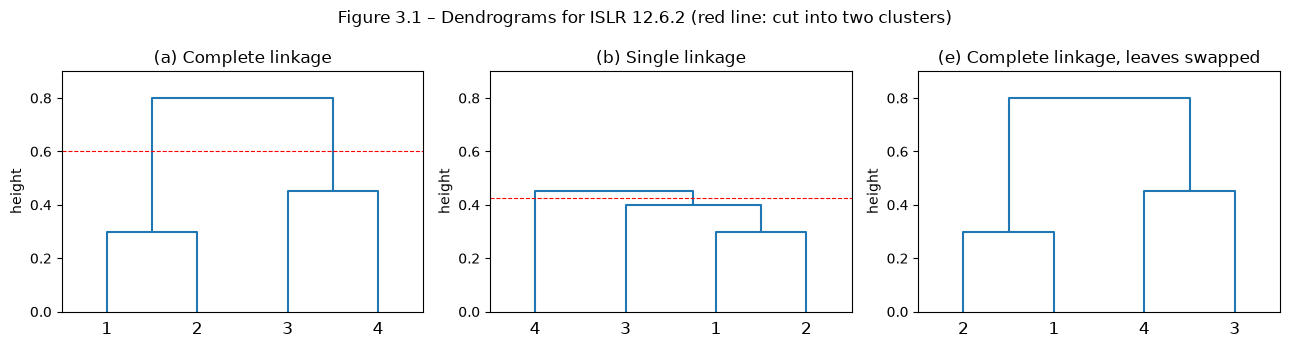

In [16]:
Z_complete = np.array([[0, 1, 0.30, 2], [2, 3, 0.45, 2], [4, 5, 0.80, 4]])
Z_single = np.array([[0, 1, 0.30, 2], [2, 4, 0.40, 3], [3, 5, 0.45, 4]])
Z_swapped = np.array([[1, 0, 0.30, 2], [3, 2, 0.45, 2], [4, 5, 0.80, 4]])
names = ["1", "2", "3", "4"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, Z, t in zip(axes, [Z_complete, Z_single, Z_swapped],
                    ["(a) Complete linkage", "(b) Single linkage", "(e) Complete linkage, leaves swapped"]):
    dendrogram(Z, labels=names, ax=ax, color_threshold=0)
    ax.set(title=t, ylabel="height", ylim=(0, 0.9))
axes[0].axhline(0.6, color="red", ls="--", lw=0.8)
axes[1].axhline(0.425, color="red", ls="--", lw=0.8)
fig.suptitle("Figure 3.1 – Dendrograms for ISLR 12.6.2 (red line: cut into two clusters)", fontsize=12)
plt.tight_layout()
plt.show()